# DA241o Assignment 3, Notebook 2: Regression Analysis

**Team 9, Hidden Layers.** *Price Dispersion and the Brand Premium for Chemically Identical Medicines on Indian E-Pharmacies under DPCO Price Control.*

**Purpose.** Estimate the two listing-level OLS models from Assignment 2, with inference suited to 15 clusters, and run the robustness checks.

**Input.** `outputs/listings_clean.csv`, written by Notebook 1.

**Outputs.** Tables 6 and 7, the variance inflation factors, the full regression output, and Figure 5 (`figure5_robustness.png`, the capped coefficient under each robustness check), all in `outputs/`.

**To run on Colab.** Choose *Runtime > Run all* and upload `listings_clean.csv` when prompted. The last cell downloads the results.

## 1. Setup

### 1.1 Required packages

This notebook needs pandas, numpy and scipy, plus `statsmodels` for the OLS models and variance inflation factors. The cell below checks whether each package can be imported and, only if one is missing, installs it with `pip` into **the Python running this kernel** (`sys.executable`), so it works whichever interpreter or Colab runtime is selected. If nothing is missing, it installs nothing and does not go online.

It then prints the Python and package versions, as a record of the environment that produced the outputs.

In [1]:
import importlib.util, subprocess, sys

REQUIRED = {"statsmodels": "statsmodels"}  # import name -> pip name
missing = [pip for mod, pip in REQUIRED.items() if importlib.util.find_spec(mod) is None]
if missing:
    print("Installing:", missing)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *missing])
    importlib.invalidate_caches()
else:
    print("All required packages present.")

import numpy, pandas, scipy, statsmodels
print(f"Python {sys.version.split()[0]} | " + " | ".join(
    f"{m.__name__} {m.__version__}" for m in (numpy, pandas, scipy, statsmodels)))

All required packages present.
Python 3.13.7 | numpy 2.3.3 | pandas 2.3.2 | scipy 1.16.2 | statsmodels 0.15.0


In [2]:
import sys, time, shutil
from pathlib import Path

import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy import stats as sps
from statsmodels.stats.outliers_influence import variance_inflation_factor
from IPython.display import display

IN_COLAB = "google.colab" in sys.modules
OUT = Path("outputs")
OUT.mkdir(exist_ok=True)
PATH = OUT / "listings_clean.csv"
if not PATH.exists() and Path("listings_clean.csv").exists():
    PATH = Path("listings_clean.csv")
if IN_COLAB and not PATH.exists():
    from google.colab import files
    files.upload()
    PATH = Path("listings_clean.csv")

pd.set_option("display.max_columns", 40, "display.width", 200, "display.max_rows", 120)
B = 9999          # wild bootstrap replications
SEED = 20261015

df = pd.read_csv(PATH)
df["log_premium_p10"] = np.log(df["premium_over_p10"])
df["log_premium_min"] = np.log(df["premium_over_min"])
df["log_premium_ja"] = np.log(df["premium_over_ja"])
df["n_substitutes_100"] = df["n_substitutes"] / 100     # coefficient reads per 100 substitutes

assert len(df) == 2150 and df["formulation_id"].nunique() == 15
assert df["is_anchor"].sum() == 15 and df["cheaper_alt_shown"].sum() == 87

LARGE_CAPPED, LARGE_UNCAPPED = ["AZI500", "TEL40"], ["LEV5", "RAB20", "ROS10"]
LARGE = LARGE_CAPPED + LARGE_UNCAPPED

def save(table, name, index=True):
    table.to_csv(OUT / f"{name}.csv", index=index)
    display(table)

## 2. Models

For listing $i$ in formulation $j$:

$$\text{Spec 1: } \log(\text{premium\_over\_p10})_{ij} = \alpha + \beta_1\text{dpco\_capped}_j + \beta_2\text{is\_anchor}_{ij} + \beta_3\text{cheaper\_alt\_shown}_{ij} + \beta_4\text{ja\_available}_j + \gamma' X_{ij} + \varepsilon_{ij}$$

$$\text{Spec 2: } \log(\text{premium\_over\_p10})_{ij} = \alpha_j + \beta_2\text{is\_anchor}_{ij} + \beta_3\text{cheaper\_alt\_shown}_{ij} + \gamma' X_{ij} + \varepsilon_{ij}$$

$X_{ij}$ holds `log_pack_units`, `n_substitutes`, `chronic` and `bought_recently_shown`. `n_substitutes` is entered per 100 substitutes for readability. Spec 2's fixed effects absorb everything constant within a formulation, including DPCO status, Jan Aushadhi availability, `n_substitutes` and `chronic`.

A coefficient $b$ implies a $100(e^b - 1)\%$ difference in the premium.

## 3. Wild cluster bootstrap

With only 15 clusters, conventional clustered t-tests over-reject (Cameron et al., 2008). This is the **restricted** wild cluster bootstrap-t with **Webb six-point weights**. It suits few clusters better than two-point weights because 15 clusters have many more distinct weight draws.

For each coefficient:

1. Estimate the model with the null ($\beta_k = 0$) imposed, which gives fitted values and residuals.
2. For each replication, multiply every cluster's residuals by one Webb draw and rebuild the outcome.
3. Re-estimate the full model and compute the clustered t-statistic.
4. The p-value is the share of bootstrap t-statistics at least as large in absolute value as the observed t.

The CR1 small-sample correction matches statsmodels, and a test below confirms the two give the same t-statistic.

In [3]:
WEBB = np.array([-np.sqrt(1.5), -1, -np.sqrt(.5), np.sqrt(.5), 1, np.sqrt(1.5)])

def cluster_t(X, y, g, G, k_idx):
    """Coefficient and CR1 clustered t-statistic for column k_idx. y may hold one column per replication."""
    n, k = X.shape
    XtXi = np.linalg.pinv(X.T @ X)
    b = XtXi @ (X.T @ y)
    e = y - X @ b
    q = X @ XtXi[k_idx]                     # the k_idx row of the sandwich bread, by observation
    score = np.zeros((G,) + y.shape[1:])
    np.add.at(score, g, q[:, None] * e if y.ndim == 2 else q * e)
    adj = G / (G - 1) * (n - 1) / (n - k)
    se = np.sqrt(adj * (score ** 2).sum(axis=0))
    return b[k_idx], se, b[k_idx] / se

def wild_p(X, y, g, k_idx, B=B, seed=SEED, chunk=500):
    """Restricted wild cluster bootstrap p-value for H0: coefficient k_idx = 0."""
    G = g.max() + 1
    _, _, t_obs = cluster_t(X, y, g, G, k_idx)
    Xr = np.delete(X, k_idx, axis=1)
    fit = Xr @ np.linalg.lstsq(Xr, y, rcond=None)[0]
    u = y - fit
    rng = np.random.default_rng(seed + k_idx)
    hits, done = 0, 0
    while done < B:
        m = min(chunk, B - done)
        W = rng.choice(WEBB, size=(G, m))
        ystar = fit[:, None] + u[:, None] * W[g]
        hits += (np.abs(cluster_t(X, ystar, g, G, k_idx)[2]) >= abs(t_obs)).sum()
        done += m
    return (hits + 1) / (B + 1)

### Checks on the bootstrap code

First, the t-statistic must equal the one from statsmodels. Second, a simulation with a true null. A sound test rejects about 5% of the time. Two designs are used: 15 **equal** clusters, as a control on the code, and clusters shaped like **this sample**, where the capped group holds the two largest formulations. If the sample-shaped rate is above 5%, the p-values below are somewhat too small and borderline results need care.

In [4]:
sim_rng = np.random.default_rng(1)
SAMPLE_SIZES = np.array([443, 91, 34, 436, 200, 65, 66, 170, 146, 57, 8, 65, 149, 135, 85])   # first five are capped

def simulate(sizes):
    g = np.repeat(np.arange(15), sizes)
    d = (np.arange(15) < 5).astype(float)[g]            # 5 of 15 clusters capped, with no true effect
    x = sim_rng.normal(size=len(g))
    y = .3 * x + sim_rng.normal(scale=.5, size=15)[g] + sim_rng.normal(size=len(g))
    return g, np.column_stack([np.ones(len(g)), d, x]), y

g, X_, y_ = simulate(SAMPLE_SIZES // 4 + 2)
sm_fit = sm.OLS(y_, X_).fit(cov_type="cluster", cov_kwds={"groups": g})
assert abs(sm_fit.tvalues[1] - cluster_t(X_, y_, g, 15, 1)[2]) < 1e-8
print("t-statistic matches statsmodels.")

t0, SIMS, rows = time.time(), 2000, []
for label, sizes in [("Equal clusters", np.full(15, 100)), ("Sample-shaped clusters", SAMPLE_SIZES // 4 + 2)]:
    wild, conv = 0, 0
    for _ in range(SIMS):
        g, X_, y_ = simulate(sizes)
        wild += wild_p(X_, y_, g, 1, B=399, seed=int(sim_rng.integers(1e9))) <= .05
        conv += 2 * sps.t.sf(abs(cluster_t(X_, y_, g, 15, 1)[2]), 14) <= .05
    rows.append({"design": label, "wild_bootstrap": wild / SIMS, "conventional_cluster": conv / SIMS,
                 "monte_carlo_se": np.sqrt(.05 * .95 / SIMS)})
print(f"Rejection rates at 5% under a true null, {SIMS} simulations each ({time.time() - t0:.0f}s)")
save(pd.DataFrame(rows).round(4), "table_bootstrap_size_check", index=False)

t-statistic matches statsmodels.
Rejection rates at 5% under a true null, 2000 simulations each (88s)


,design,wild_bootstrap,conventional_cluster,monte_carlo_se
0,Equal clusters,0.053,0.0705,0.0049
1,Sample-shaped clusters,0.070,0.1110,0.0049


## 4. Estimation helpers

`fit_model` keeps regressors in the order given and drops any that are perfectly collinear in the sample at hand, printing what it dropped. Conventional p-values use a t distribution with $G-1$ degrees of freedom. `single_cluster` lists regressors identified by a single cluster, whose clustered standard errors cannot be trusted.

In [5]:
SPEC1 = ["dpco_capped", "is_anchor", "cheaper_alt_shown", "ja_available", "log_pack_units",
         "n_substitutes_100", "chronic", "bought_recently_shown"]
SPEC2 = ["is_anchor", "cheaper_alt_shown", "log_pack_units", "bought_recently_shown"]
KEY = {"dpco_capped": "b1", "is_anchor": "b2", "cheaper_alt_shown": "b3", "ja_available": "b4"}

def full_rank(M, names):
    keep = []
    for i, c in enumerate(names):
        if np.linalg.matrix_rank(M[:, keep + [i]], tol=1e-8) == len(keep) + 1:
            keep.append(i)
    return keep

def fit_model(d, dv, xvars, fe=False, extra=None, wild_for=None, B_=B):
    d = d.dropna(subset=[dv]).copy()
    gid, _ = pd.factorize(d["formulation_id"])
    G = gid.max() + 1
    names = list(xvars) + (extra or [])
    A = d[names].astype(float)
    if fe:
        F = pd.get_dummies(d["formulation_id"], dtype=float)
        Xd = pd.concat([A, F], axis=1)
    else:
        Xd = pd.concat([A, pd.Series(1., index=d.index, name="const")], axis=1)
        Xd = Xd[["const"] + list(A.columns)]
    M = Xd.to_numpy()
    keep = full_rank(M, list(Xd.columns))
    dropped = [c for i, c in enumerate(Xd.columns) if i not in keep]
    if dropped:
        print(f"    collinear, dropped: {dropped}")
    Xd, M = Xd.iloc[:, keep], M[:, keep]
    y = d[dv].to_numpy()
    res = sm.OLS(y, Xd).fit(cov_type="cluster", cov_kwds={"groups": gid, "use_correction": True, "df_correction": True}, use_t=True)
    cols = [c for c in names if c in Xd.columns]
    rows = []
    for c in cols:
        k = list(Xd.columns).index(c)
        b, se, t = cluster_t(M, y, gid, G, k)
        p = 2 * sps.t.sf(abs(t), G - 1)
        n1 = d.groupby("formulation_id")[c].mean()
        constant_within = (d.groupby("formulation_id")[c].nunique() == 1).all()
        small_side = min((n1 > n1.mean()).sum(), (n1 <= n1.mean()).sum()) if constant_within else None
        rows.append({"variable": c, "coef": b, "se_cluster": se, "t": t, "p_cluster": p,
                     "p_wild": wild_p(M, y, gid, k, B=B_) if (wild_for is None or c in wild_for) else np.nan,
                     "pct_effect": 100 * (np.exp(b) - 1),
                     "single_cluster": bool(constant_within and small_side == 1)})
    return pd.DataFrame(rows).set_index("variable"), res, dict(N=len(d), G=G, R2=res.rsquared, dropped=dropped)

## 5. Collinearity among the formulation-level regressors

`dpco_capped`, `ja_available`, `n_substitutes` and `chronic` vary across only 15 formulations.

In [6]:
Xv = sm.add_constant(df[SPEC1].astype(float))
vif = pd.DataFrame({"VIF_listing_level": [variance_inflation_factor(Xv.values, i) for i in range(1, Xv.shape[1])]}, index=SPEC1)
form = df.groupby("formulation_id")[["dpco_capped", "ja_available", "n_substitutes_100", "chronic"]].first()
Xf = sm.add_constant(form.astype(float))
vif["VIF_formulation_level"] = pd.Series([variance_inflation_factor(Xf.values, i) for i in range(1, Xf.shape[1])], index=form.columns)
save(vif.round(2), "table_vif")
save(form.corr().round(2), "table_formulation_correlations")

,VIF_listing_level,VIF_formulation_level
dpco_capped,2.19,1.42
is_anchor,1.03,NaN
cheaper_alt_shown,1.01,NaN
ja_available,1.38,1.13
log_pack_units,3.16,NaN
n_substitutes_100,6.07,2.31
chronic,4.28,2.16
bought_recently_shown,1.14,NaN


,dpco_capped,ja_available,n_substitutes_100,chronic
dpco_capped,1.00,0.28,0.32,0.11
ja_available,0.28,1.00,0.01,0.21
n_substitutes_100,0.32,0.01,1.00,-0.64
chronic,0.11,0.21,-0.64,1.00


## 6. Table 6: Main results

Each coefficient has its clustered standard error, conventional p-value, wild cluster bootstrap p-value and percentage effect. The effective sample size is next to each: $\beta_1$ rests on 5 vs 10 formulations, $\beta_4$ on 13 vs 2, $\beta_2$ on 15 anchors and $\beta_3$ on 87 flagged listings.

In [7]:
t0 = time.time()
s1, r1, i1 = fit_model(df, "log_premium_p10", SPEC1)
s2, r2, i2 = fit_model(df, "log_premium_p10", SPEC2, fe=True)
print(f"Done in {time.time() - t0:.0f}s")

EFFECTIVE = {"dpco_capped": "5 vs 10 formulations", "is_anchor": "15 anchors", "cheaper_alt_shown": "87 flagged listings",
             "ja_available": "13 vs 2 formulations", "n_substitutes_100": "15 formulations", "chronic": "11 vs 4 formulations",
             "log_pack_units": "2,150 listings", "bought_recently_shown": f"{int(df['bought_recently_shown'].sum())} listings shown"}
t6 = s1.drop(columns="single_cluster").merge(s2.drop(columns="single_cluster"), how="outer", left_index=True, right_index=True,
                                             suffixes=("_spec1", "_spec2")).reindex(SPEC1)
t6.insert(0, "effective_sample", pd.Series(EFFECTIVE))
save(t6.round(3), "table6_main_results")
print(f"Spec 1: N={i1['N']}, clusters={i1['G']}, R2={i1['R2']:.3f}.  Spec 2: N={i2['N']}, clusters={i2['G']}, R2={i2['R2']:.3f} (formulation effects included).")

with open(OUT / "appendix_full_regression_output.txt", "w", encoding="utf-8") as f:
    f.write("SPEC 1\n" + r1.summary().as_text() + "\n\nSPEC 2\n" + r2.summary().as_text())

Done in 13s


,effective_sample,coef_spec1,se_cluster_spec1,t_spec1,p_cluster_spec1,p_wild_spec1,pct_effect_spec1,coef_spec2,se_cluster_spec2,t_spec2,p_cluster_spec2,p_wild_spec2,pct_effect_spec2
variable,,,,,,,,,,,,,
dpco_capped,5 vs 10 formulations,-0.118,0.039,-3.028,0.009,0.017,-11.106,NaN,NaN,NaN,NaN,NaN,NaN
is_anchor,15 anchors,0.319,0.115,2.764,0.015,0.011,37.581,0.323,0.114,2.835,0.013,0.008,38.060
cheaper_alt_shown,87 flagged listings,-0.229,0.030,-7.550,0.000,0.000,-20.446,-0.210,0.034,-6.167,0.000,0.000,-18.955
ja_available,13 vs 2 formulations,-0.038,0.028,-1.342,0.201,0.448,-3.689,NaN,NaN,NaN,NaN,NaN,NaN
log_pack_units,"2,150 listings",0.088,0.043,2.048,0.060,0.027,9.214,0.025,0.038,0.668,0.515,0.477,2.553
n_substitutes_100,15 formulations,-0.008,0.009,-0.966,0.350,0.477,-0.833,NaN,NaN,NaN,NaN,NaN,NaN
chronic,11 vs 4 formulations,-0.131,0.044,-2.996,0.010,0.188,-12.256,NaN,NaN,NaN,NaN,NaN,NaN
bought_recently_shown,427 listings shown,0.105,0.038,2.721,0.017,0.008,11.043,0.125,0.036,3.436,0.004,0.002,13.287


Spec 1: N=2150, clusters=15, R2=0.167.  Spec 2: N=2150, clusters=15, R2=0.194 (formulation effects included).


Coefficients significant under conventional clustering but not under the wild bootstrap should not be claimed as findings. This cell lists any.

In [8]:
for lab, s in [("Spec 1", s1), ("Spec 2", s2)]:
    gap = s[(s["p_cluster"] < .05) & (s["p_wild"] >= .05)]
    print(f"{lab}: significant at 5% only under conventional clustering: {gap.index.tolist() or 'none'}")
    print(f"{lab}: significant at 5% under the wild bootstrap: {s.index[s['p_wild'] < .05].tolist() or 'none'}")

Spec 1: significant at 5% only under conventional clustering: ['chronic']
Spec 1: significant at 5% under the wild bootstrap: ['dpco_capped', 'is_anchor', 'cheaper_alt_shown', 'log_pack_units', 'bought_recently_shown']
Spec 2: significant at 5% only under conventional clustering: none
Spec 2: significant at 5% under the wild bootstrap: ['is_anchor', 'cheaper_alt_shown', 'bought_recently_shown']


### Rupee translation of the coefficients

The percentage effect applied to the median formulation's P10 price, so a percentage can be read in rupees per tablet. This is a scale guide, since the P10 price varies widely between formulations.

In [9]:
p10_med = df.groupby("formulation_id")["p10_sp"].first().median()
rows = []
for lab, s in [("Spec 1", s1), ("Spec 2", s2)]:
    for v in ["dpco_capped", "is_anchor", "cheaper_alt_shown", "ja_available"]:
        if v in s.index:
            rows.append({"spec": lab, "variable": v, "pct_effect": s.loc[v, "pct_effect"], "p_wild": s.loc[v, "p_wild"],
                         "rs_per_tablet_at_median_p10": p10_med * s.loc[v, "pct_effect"] / 100})
print(f"Median formulation P10: Rs {p10_med:.2f} per tablet")
save(pd.DataFrame(rows).round(3), "table_coefficients_rupees", index=False)

Median formulation P10: Rs 4.65 per tablet


,spec,variable,pct_effect,p_wild,rs_per_tablet_at_median_p10
0,Spec 1,dpco_capped,-11.106,0.017,-0.516
1,Spec 1,is_anchor,37.581,0.011,1.748
2,Spec 1,cheaper_alt_shown,-20.446,0.000,-0.951
3,Spec 1,ja_available,-3.689,0.448,-0.172
4,Spec 2,is_anchor,38.060,0.008,1.770
5,Spec 2,cheaper_alt_shown,-18.955,0.000,-0.881


### Table 6b: The models with the corrected alternative variable

Notebook 1 shows that the stored `cheaper_alt_shown` misses the usual wording of the prompt, so it marks only 87 listings, mostly listings with a small saving. `alt_widget_shown` marks the 1,932 listings that show the prompt. These models replace the stored flag with the corrected variable, so β3 can be read as Assignment 2 intended. `alt_saving_pct` is not used as a regressor: the saving is worked out from the listing's own price, so it would explain the premium by construction.

In [10]:
swap = lambda v: ["alt_widget_shown" if c == "cheaper_alt_shown" else c for c in v]
c1, _, ic1 = fit_model(df, "log_premium_p10", swap(SPEC1))
c2, _, ic2 = fit_model(df, "log_premium_p10", swap(SPEC2), fe=True)
t6b = c1.drop(columns="single_cluster").merge(c2.drop(columns="single_cluster"), how="outer", left_index=True, right_index=True,
                                              suffixes=("_spec1", "_spec2")).reindex(swap(SPEC1))
n_alt = int(df["alt_widget_shown"].sum())
EFFECTIVE_C = {("alt_widget_shown" if v == "cheaper_alt_shown" else v): e for v, e in EFFECTIVE.items()}
EFFECTIVE_C["alt_widget_shown"] = f"{n_alt:,} vs {len(df) - n_alt} listings"
t6b.insert(0, "effective_sample", pd.Series(EFFECTIVE_C))
save(t6b.round(3), "table6b_corrected_alternative")
print(f"Effective sample for alt_widget_shown: {int(df['alt_widget_shown'].sum()):,} listings with the prompt, {int((1 - df['alt_widget_shown']).sum())} without.")
print(f"Spec 1: N={ic1['N']}, R2={ic1['R2']:.3f}.  Spec 2: N={ic2['N']}, R2={ic2['R2']:.3f}.")

,effective_sample,coef_spec1,se_cluster_spec1,t_spec1,p_cluster_spec1,p_wild_spec1,pct_effect_spec1,coef_spec2,se_cluster_spec2,t_spec2,p_cluster_spec2,p_wild_spec2,pct_effect_spec2
variable,,,,,,,,,,,,,
dpco_capped,5 vs 10 formulations,-0.105,0.047,-2.236,0.042,0.060,-9.974,NaN,NaN,NaN,NaN,NaN,NaN
is_anchor,15 anchors,0.340,0.122,2.794,0.014,0.002,40.562,0.321,0.119,2.705,0.017,0.001,37.856
alt_widget_shown,"1,932 vs 218 listings",0.459,0.074,6.219,0.000,0.000,58.306,0.475,0.079,6.011,0.000,0.000,60.799
ja_available,13 vs 2 formulations,-0.031,0.037,-0.845,0.413,0.425,-3.069,NaN,NaN,NaN,NaN,NaN,NaN
log_pack_units,"2,150 listings",0.087,0.032,2.742,0.016,0.007,9.074,0.053,0.034,1.530,0.148,0.060,5.396
n_substitutes_100,15 formulations,-0.016,0.010,-1.575,0.138,0.306,-1.586,NaN,NaN,NaN,NaN,NaN,NaN
chronic,11 vs 4 formulations,-0.194,0.057,-3.392,0.004,0.122,-17.627,NaN,NaN,NaN,NaN,NaN,NaN
bought_recently_shown,427 listings shown,0.163,0.048,3.416,0.004,0.002,17.700,0.180,0.045,3.960,0.001,0.002,19.742


Effective sample for alt_widget_shown: 1,932 listings with the prompt, 218 without.
Spec 1: N=2150, R2=0.325.  Spec 2: N=2150, R2=0.360.


### Table 6c: Rosuvas at its current pack

The Rosuvas anchor is priced at a discontinued 10-tablet pack (Notebook 1). These models set it to the current 15-tablet pack, ₹24.00 per tablet, with the corrected alternative variable.

In [11]:
dfix = df.copy()
dfix["log_premium_p10"] = np.log(dfix["premium_over_p10_fix"])
dfix.loc[dfix["ros_anchor_row"] == 1, "log_pack_units"] = np.log(15)
f1, _, _ = fit_model(dfix, "log_premium_p10", swap(SPEC1))
f2, _, _ = fit_model(dfix, "log_premium_p10", swap(SPEC2), fe=True)
t6c = f1.drop(columns="single_cluster").merge(f2.drop(columns="single_cluster"), how="outer", left_index=True, right_index=True,
                                              suffixes=("_spec1", "_spec2")).reindex(swap(SPEC1))
t6c.insert(0, "effective_sample", pd.Series(EFFECTIVE_C))
save(t6c.round(3), "table6c_rosuvas_current_pack")

,effective_sample,coef_spec1,se_cluster_spec1,t_spec1,p_cluster_spec1,p_wild_spec1,pct_effect_spec1,coef_spec2,se_cluster_spec2,t_spec2,p_cluster_spec2,p_wild_spec2,pct_effect_spec2
variable,,,,,,,,,,,,,
dpco_capped,5 vs 10 formulations,-0.108,0.048,-2.272,0.039,0.059,-10.236,NaN,NaN,NaN,NaN,NaN,NaN
is_anchor,15 anchors,0.406,0.129,3.141,0.007,0.001,50.036,0.388,0.128,3.041,0.009,0.001,47.415
alt_widget_shown,"1,932 vs 218 listings",0.455,0.072,6.320,0.000,0.000,57.581,0.470,0.077,6.102,0.000,0.000,60.002
ja_available,13 vs 2 formulations,-0.031,0.036,-0.841,0.415,0.427,-3.018,NaN,NaN,NaN,NaN,NaN,NaN
log_pack_units,"2,150 listings",0.088,0.032,2.733,0.016,0.006,9.227,0.054,0.036,1.507,0.154,0.058,5.546
n_substitutes_100,15 formulations,-0.015,0.010,-1.494,0.157,0.323,-1.521,NaN,NaN,NaN,NaN,NaN,NaN
chronic,11 vs 4 formulations,-0.190,0.058,-3.290,0.005,0.133,-17.292,NaN,NaN,NaN,NaN,NaN,NaN
bought_recently_shown,427 listings shown,0.159,0.047,3.404,0.004,0.002,17.234,0.176,0.045,3.946,0.001,0.002,19.228


### Table 6d: The leading brand instead of the anchor

`is_leader` replaces `is_anchor`, with the corrected alternative variable. Every leader shows a count by construction, so `bought_recently_shown` is positively tied to `is_leader`; the table is a comparison with Table 6b, not a separate test of popularity.

In [12]:
lead = lambda v: ["is_leader" if c == "is_anchor" else c for c in swap(v)]
l1, _, _ = fit_model(df, "log_premium_p10", lead(SPEC1))
l2, _, _ = fit_model(df, "log_premium_p10", lead(SPEC2), fe=True)
t6d = l1.drop(columns="single_cluster").merge(l2.drop(columns="single_cluster"), how="outer", left_index=True, right_index=True,
                                              suffixes=("_spec1", "_spec2")).reindex(lead(SPEC1))
EFFECTIVE_L = {("is_leader" if v == "is_anchor" else v): e for v, e in EFFECTIVE_C.items()}
EFFECTIVE_L["is_leader"] = "15 leaders"
t6d.insert(0, "effective_sample", pd.Series(EFFECTIVE_L))
save(t6d.round(3), "table6d_leader")

,effective_sample,coef_spec1,se_cluster_spec1,t_spec1,p_cluster_spec1,p_wild_spec1,pct_effect_spec1,coef_spec2,se_cluster_spec2,t_spec2,p_cluster_spec2,p_wild_spec2,pct_effect_spec2
variable,,,,,,,,,,,,,
dpco_capped,5 vs 10 formulations,-0.104,0.047,-2.207,0.045,0.065,-9.888,NaN,NaN,NaN,NaN,NaN,NaN
is_leader,15 leaders,0.147,0.075,1.954,0.071,0.072,15.852,0.124,0.066,1.894,0.079,0.083,13.244
alt_widget_shown,"1,932 vs 218 listings",0.457,0.074,6.189,0.000,0.000,57.895,0.473,0.079,5.995,0.000,0.000,60.545
ja_available,13 vs 2 formulations,-0.032,0.038,-0.837,0.417,0.434,-3.133,NaN,NaN,NaN,NaN,NaN,NaN
log_pack_units,"2,150 listings",0.086,0.032,2.715,0.017,0.010,9.010,0.053,0.034,1.569,0.139,0.049,5.470
n_substitutes_100,15 formulations,-0.016,0.010,-1.603,0.131,0.302,-1.618,NaN,NaN,NaN,NaN,NaN,NaN
chronic,11 vs 4 formulations,-0.195,0.058,-3.396,0.004,0.121,-17.744,NaN,NaN,NaN,NaN,NaN,NaN
bought_recently_shown,427 listings shown,0.169,0.047,3.584,0.003,0.002,18.357,0.186,0.045,4.146,0.001,0.001,20.426


### Table 6e: Exact randomisation test for the formulation-level coefficients

The wild bootstrap slightly over-rejects on clusters shaped like this sample, so $\beta_1$ is also tested a different way. There are only $\binom{15}{5} = 3{,}003$ ways to label 5 of the 15 formulations as capped. The model is refitted under every labelling, and the p-value is the share of labellings whose t-statistic is at least as extreme as the real one. The same is done for $\beta_4$ with its $\binom{15}{2} = 105$ labellings.

This uses no asymptotic theory or cluster-count assumption. It asks whether the real labelling stands out among all labellings of these formulations. DPCO status was not randomly assigned, so a small p-value shows the capped group differs, not that capping caused the difference. With 105 labellings, the smallest possible p-value for $\beta_4$ is about .0095.

In [13]:
from itertools import combinations

def randomisation(d, dv, xvars, var):
    d = d.dropna(subset=[dv])
    gid, forms = pd.factorize(d["formulation_id"])
    G = len(forms)
    Xd = pd.concat([pd.Series(1., index=d.index, name="const"), d[xvars].astype(float)], axis=1)
    M, y, k = Xd.to_numpy().copy(), d[dv].to_numpy(), list(Xd.columns).index(var)
    real = d.groupby("formulation_id")[var].first().reindex(forms).to_numpy()
    size = int(real.sum()) if var == "dpco_capped" else int((1 - real).sum())
    b_obs, _, t_obs = cluster_t(M, y, gid, G, k)
    ts, bs = [], []
    for combo in combinations(range(G), size):
        lab = np.isin(np.arange(G), combo).astype(float)
        if var == "ja_available":
            lab = 1 - lab
        M[:, k] = lab[gid]
        b, _, t = cluster_t(M, y, gid, G, k)
        ts.append(t); bs.append(b)
    ts, bs = np.array(ts), np.array(bs)
    return {"coef": b_obs, "pct_effect": 100 * (np.exp(b_obs) - 1), "labellings": len(ts),
            "p_two_sided_t": (np.abs(ts) >= abs(t_obs) - 1e-9).mean(),
            "p_one_sided_t": (ts <= t_obs + 1e-9).mean(),
            "p_two_sided_coef": (np.abs(bs) >= abs(b_obs) - 1e-9).mean(),
            "p_one_sided_coef": (bs <= b_obs + 1e-9).mean()}

t0 = time.time()
cases = [("Stored flag (Table 6)", df, SPEC1), ("Corrected flag (Table 6b)", df, swap(SPEC1)),
         ("Corrected flag, Rosuvas current pack (Table 6c)", dfix, swap(SPEC1)), ("Leader instead of anchor (Table 6d)", df, lead(SPEC1))]
rows = [{"model": lab, "coefficient": v, **randomisation(d, "log_premium_p10", xs, v)}
        for lab, d, xs in cases for v in ["dpco_capped", "ja_available"]]
print(f"Done in {time.time() - t0:.0f}s")
save(pd.DataFrame(rows).round(3), "table6e_randomisation_test", index=False)

Done in 4s


,model,coefficient,coef,pct_effect,labellings,p_two_sided_t,p_one_sided_t,p_two_sided_coef,p_one_sided_coef
0,Stored flag (Table 6),dpco_capped,-0.118,-11.106,3003,0.039,0.018,0.035,0.023
1,Stored flag (Table 6),ja_available,-0.038,-3.689,105,0.495,0.314,0.648,0.343
2,Corrected flag (Table 6b),dpco_capped,-0.105,-9.974,3003,0.069,0.025,0.070,0.041
3,Corrected flag (Table 6b),ja_available,-0.031,-3.069,105,0.648,0.371,0.714,0.390
4,"Corrected flag, Rosuvas current pack (Table 6c)",dpco_capped,-0.108,-10.236,3003,0.066,0.023,0.066,0.038
5,"Corrected flag, Rosuvas current pack (Table 6c)",ja_available,-0.031,-3.018,105,0.648,0.371,0.724,0.381
6,Leader instead of anchor (Table 6d),dpco_capped,-0.104,-9.888,3003,0.071,0.026,0.071,0.041
7,Leader instead of anchor (Table 6d),ja_available,-0.032,-3.133,105,0.648,0.371,0.667,0.362


## 7. Table 7: Robustness

- (a) Without the five large formulations, which Assignment 2 promised, and without each of the two subsets alone: the two large capped ones (TEL40, AZI500) and the three large uncapped ones (ROS10, RAB20, LEV5). Dropping TEL40 and AZI500 leaves 3 capped formulations, so that row is a direction check, not a test.
- (b) Top and bottom 1% trimmed within each formulation, which Assignment 2 promised. Premiums keep their original P10 base. Anchors are often the top price, so this trim removes several of the 15 anchors and is no longer a fair test of $\beta_2$. A second row trims the same way but keeps every anchor.
- (c) `log(premium_over_min)` and `log(premium_over_ja)` as the dependent variable.
- (d) Therapeutic-category dummies added to Spec 1, with Antidiabetic as the base. The acute formulations' categories determine `chronic`, so one category dummy is dropped as collinear.
- (e) The repeated rows resolved by keeping the first of each group.

`*` marks a coefficient identified by a single cluster, whose p-values should not be read as tests.

In [14]:
g = df.groupby("formulation_id")["sp_unit"]
trimmed = df[(df["sp_unit"] >= g.transform(lambda s: s.quantile(.01))) & (df["sp_unit"] <= g.transform(lambda s: s.quantile(.99)))]
print(f"Trim removes {len(df) - len(trimmed)} listings, including {15 - int(trimmed['is_anchor'].sum())} anchors.")

cats = pd.get_dummies(df["therapeutic_category"], prefix="cat", dtype=float).drop(columns="cat_Antidiabetic")
withcat = pd.concat([df, cats], axis=1)

VARIANTS = [
    ("Baseline", df, "log_premium_p10", {}),
    ("(a) Without 5 large", df[~df["formulation_id"].isin(LARGE)], "log_premium_p10", {}),
    ("(a) Without large capped", df[~df["formulation_id"].isin(LARGE_CAPPED)], "log_premium_p10", {}),
    ("(a) Without large uncapped", df[~df["formulation_id"].isin(LARGE_UNCAPPED)], "log_premium_p10", {}),
    ("(b) 1% trimmed", trimmed, "log_premium_p10", {}),
    ("(b) 1% trimmed, anchors kept", df[df.index.isin(trimmed.index) | (df["is_anchor"] == 1)], "log_premium_p10", {}),
    ("(c) DV: log premium over min", df, "log_premium_min", {}),
    ("(c) DV: log premium over JA", df, "log_premium_ja", {}),
    ("(d) Category dummies", withcat, "log_premium_p10", {"extra": list(cats.columns), "spec1_only": True}),
    ("(e) Repeated rows resolved", df[df["repeat_extra"] == 0], "log_premium_p10", {}),
]

t0, rows = time.time(), []
for label, d, dv, opt in VARIANTS:
    print(label)
    a, _, ia = fit_model(d, dv, SPEC1, extra=opt.get("extra"), wild_for=list(KEY))
    row = {"check": label, "N": ia["N"], "clusters": ia["G"]}
    for v, b in KEY.items():
        if v in a.index:
            mark = "*" if a.loc[v, "single_cluster"] else ""
            row[f"{b}_{v}"] = f"{a.loc[v, 'coef']:.3f}{mark}"
            row[f"{b}_p_wild"] = round(a.loc[v, "p_wild"], 3)
    if not opt.get("spec1_only"):
        b2, _, _ = fit_model(d, dv, SPEC2, fe=True, wild_for=["is_anchor", "cheaper_alt_shown"])
        for v, tag in [("is_anchor", "fe_b2"), ("cheaper_alt_shown", "fe_b3")]:
            row[f"{tag}_{v}"] = f"{b2.loc[v, 'coef']:.3f}"
            row[f"{tag}_p_wild"] = round(b2.loc[v, "p_wild"], 3)
    rows.append(row)
t7 = pd.DataFrame(rows).set_index("check")
print(f"Done in {time.time() - t0:.0f}s")
save(t7, "table7_robustness")

Trim removes 55 listings, including 6 anchors.
Baseline
(a) Without 5 large
(a) Without large capped
(a) Without large uncapped
(b) 1% trimmed
(b) 1% trimmed, anchors kept
(c) DV: log premium over min
(c) DV: log premium over JA
    collinear, dropped: ['ja_available']
(d) Category dummies
    collinear, dropped: ['cat_NSAID']
(e) Repeated rows resolved
Done in 52s


,N,clusters,b1_dpco_capped,b1_p_wild,b2_is_anchor,b2_p_wild,b3_cheaper_alt_shown,b3_p_wild,b4_ja_available,b4_p_wild,fe_b2_is_anchor,fe_b2_p_wild,fe_b3_cheaper_alt_shown,fe_b3_p_wild
check,,,,,,,,,,,,,,
Baseline,2150,15,-0.118,0.017,0.319,0.011,-0.229,0.000,-0.038,0.448,0.323,0.008,-0.210,0.000
(a) Without 5 large,841,10,-0.126,0.036,0.434,0.008,-0.224,0.002,-0.032*,0.702,0.418,0.014,-0.190,0.004
(a) Without large capped,1271,13,-0.112,0.052,0.354,0.012,-0.236,0.000,-0.007,0.765,0.347,0.011,-0.210,0.001
(a) Without large uncapped,1720,12,-0.105,0.083,0.379,0.005,-0.224,0.003,0.002*,0.952,0.374,0.006,-0.200,0.002
(b) 1% trimmed,2095,15,-0.103,0.035,0.084,0.426,-0.232,0.001,-0.050,0.333,0.081,0.398,-0.214,0.000
"(b) 1% trimmed, anchors kept",2101,15,-0.106,0.030,0.276,0.026,-0.235,0.000,-0.048,0.336,0.274,0.021,-0.216,0.000
(c) DV: log premium over min,2150,15,-0.138,0.737,0.126,0.483,-0.290,0.001,-0.990,0.585,0.323,0.008,-0.210,0.000
(c) DV: log premium over JA,1996,13,-0.185,0.676,0.231,0.196,-0.329,0.004,NaN,NaN,0.335,0.022,-0.215,0.000
(d) Category dummies,2150,15,-0.098,0.467,0.320,0.010,-0.225,0.001,-0.026,0.586,NaN,NaN,NaN,NaN


### Table 7b: Robustness with the corrected alternative variable

Table 7 keeps `cheaper_alt_shown`, as submitted in Assignment 2. Table 6b is the better reading of the models, so this table repeats every check in Table 7 with `alt_widget_shown` in its place. Nothing else changes: the same samples, dependent variables and bootstrap.

In [15]:
KEY_C = {"alt_widget_shown" if v == "cheaper_alt_shown" else v: b for v, b in KEY.items()}

t0, rows = time.time(), []
for label, d, dv, opt in VARIANTS:
    print(label)
    a, _, ia = fit_model(d, dv, swap(SPEC1), extra=opt.get("extra"), wild_for=list(KEY_C))
    row = {"check": label, "N": ia["N"], "clusters": ia["G"]}
    for v, b in KEY_C.items():
        if v in a.index:
            mark = "*" if a.loc[v, "single_cluster"] else ""
            row[f"{b}_{v}"] = f"{a.loc[v, 'coef']:.3f}{mark}"
            row[f"{b}_p_wild"] = round(a.loc[v, "p_wild"], 3)
    if not opt.get("spec1_only"):
        b2, _, _ = fit_model(d, dv, swap(SPEC2), fe=True, wild_for=["is_anchor", "alt_widget_shown"])
        for v, tag in [("is_anchor", "fe_b2"), ("alt_widget_shown", "fe_b3")]:
            row[f"{tag}_{v}"] = f"{b2.loc[v, 'coef']:.3f}"
            row[f"{tag}_p_wild"] = round(b2.loc[v, "p_wild"], 3)
    rows.append(row)
t7b = pd.DataFrame(rows).set_index("check")
print(f"Done in {time.time() - t0:.0f}s")
save(t7b, "table7b_robustness_corrected")

Baseline
(a) Without 5 large
(a) Without large capped
(a) Without large uncapped
(b) 1% trimmed
(b) 1% trimmed, anchors kept
(c) DV: log premium over min
(c) DV: log premium over JA
    collinear, dropped: ['ja_available']
(d) Category dummies
    collinear, dropped: ['cat_NSAID']
(e) Repeated rows resolved
Done in 54s


,N,clusters,b1_dpco_capped,b1_p_wild,b2_is_anchor,b2_p_wild,b3_alt_widget_shown,b3_p_wild,b4_ja_available,b4_p_wild,fe_b2_is_anchor,fe_b2_p_wild,fe_b3_alt_widget_shown,fe_b3_p_wild
check,,,,,,,,,,,,,,
Baseline,2150,15,-0.105,0.060,0.340,0.002,0.459,0.000,-0.031,0.425,0.321,0.001,0.475,0.000
(a) Without 5 large,841,10,-0.116,0.085,0.436,0.003,0.426,0.003,-0.325*,0.581,0.421,0.004,0.439,0.002
(a) Without large capped,1271,13,-0.109,0.086,0.393,0.002,0.511,0.000,-0.018,0.740,0.365,0.003,0.537,0.000
(a) Without large uncapped,1720,12,-0.095,0.128,0.363,0.004,0.383,0.001,-0.264*,0.566,0.357,0.002,0.389,0.001
(b) 1% trimmed,2095,15,-0.092,0.131,0.084,0.238,0.368,0.000,-0.043,0.240,0.084,0.090,0.383,0.000
"(b) 1% trimmed, anchors kept",2101,15,-0.096,0.098,0.302,0.007,0.363,0.000,-0.045,0.242,0.284,0.004,0.379,0.000
(c) DV: log premium over min,2150,15,-0.123,0.768,0.150,0.456,0.529,0.001,-0.984,0.576,0.321,0.001,0.475,0.000
(c) DV: log premium over JA,1996,13,-0.169,0.703,0.238,0.236,0.501,0.000,NaN,NaN,0.340,0.002,0.451,0.000
(d) Category dummies,2150,15,-0.087,0.530,0.318,0.002,0.471,0.000,-0.354,0.523,NaN,NaN,NaN,NaN


## 8. Summary for the hypothesis revisit

The numbers below feed the verdicts on H1 and H5 to H7. H1 and H7 are associations only, since there is one shared molecule and DPCO status follows NLEM inclusion. Under Assignment 2's fallback, if these are inconclusive the report leads with the formulation-level evidence and effect sizes from Notebook 1.

In [16]:
summary = pd.DataFrame([
    {"hypothesis": "H1 capped has smaller premium", "coefficient": "b1, Spec 1", "predicted": "negative", **s1.loc["dpco_capped", ["coef", "pct_effect", "p_cluster", "p_wild"]].to_dict()},
    {"hypothesis": "H5 anchor has higher premium", "coefficient": "b2, Spec 2", "predicted": "positive", **s2.loc["is_anchor", ["coef", "pct_effect", "p_cluster", "p_wild"]].to_dict()},
    {"hypothesis": "H6 flag has lower premium", "coefficient": "b3, Spec 2", "predicted": "negative", **s2.loc["cheaper_alt_shown", ["coef", "pct_effect", "p_cluster", "p_wild"]].to_dict()},
    {"hypothesis": "H7 JA stocked has smaller premium", "coefficient": "b4, Spec 1", "predicted": "negative", **s1.loc["ja_available", ["coef", "pct_effect", "p_cluster", "p_wild"]].to_dict()},
])
save(summary.round(3), "table_hypothesis_inputs", index=False)

,hypothesis,coefficient,predicted,coef,pct_effect,p_cluster,p_wild
0,H1 capped has smaller premium,"b1, Spec 1",negative,-0.118,-11.106,0.009,0.017
1,H5 anchor has higher premium,"b2, Spec 2",positive,0.323,38.060,0.013,0.008
2,H6 flag has lower premium,"b3, Spec 2",negative,-0.210,-18.955,0.000,0.000
3,H7 JA stocked has smaller premium,"b4, Spec 1",negative,-0.038,-3.689,0.201,0.448


## 9. Robustness figure

Figure 5 shows the capped coefficient $\beta_1$, as a percentage difference in the premium, under every robustness check in Tables 7 and 7b, for the corrected flag (lead model) and the as-submitted flag. Filled markers have a wild bootstrap p-value below .05. The cells fit no models: they read `outputs/table7_robustness.csv` and `outputs/table7b_robustness_corrected.csv`, so they run after Section 7, and write `outputs/figure5_robustness.png`.

Figure 6, the annual cost of chronic medicines, is drawn in Notebook 1, which writes its input tables.

In [17]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

SOURCE = ("Source: Tata 1mg listings recorded 12 and 13 October 2026; NPPA S.O. 1575(E); "
          "PMBI product list; authors' calculations.")
RED, ORANGE, BLUE, GREEN, INK, MUTED = "#B5202A", "#D98C2B", "#1877B0", "#3F8F4A", "#222222", "#6B6B6B"
plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False})

## Figure 5. Robustness of the capped coefficient

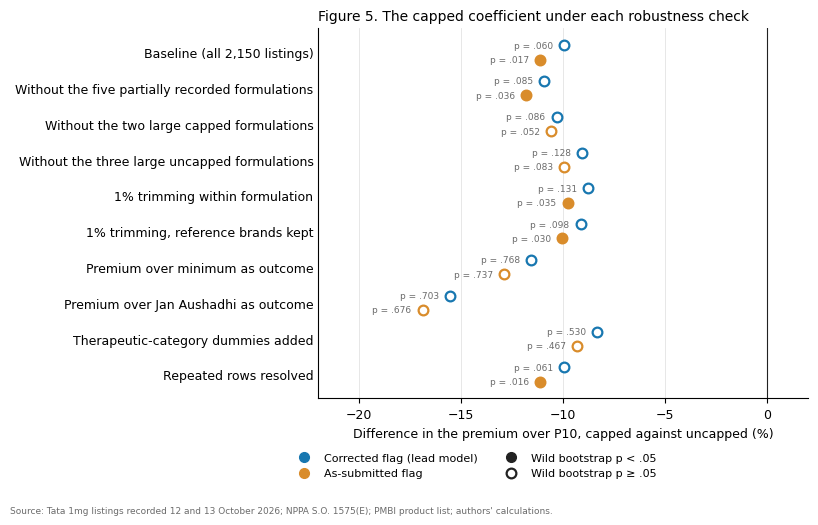

In [18]:
def pct(b):
    """Log-point coefficient to a percentage difference in the premium."""
    return 100 * (np.exp(b) - 1)

corr = pd.read_csv(f"{OUT}/table7b_robustness_corrected.csv")
subm = pd.read_csv(f"{OUT}/table7_robustness.csv")
labels = {
    "Baseline": "Baseline (all 2,150 listings)",
    "(a) Without 5 large": "Without the five partially recorded formulations",
    "(a) Without large capped": "Without the two large capped formulations",
    "(a) Without large uncapped": "Without the three large uncapped formulations",
    "(b) 1% trimmed": "1% trimming within formulation",
    "(b) 1% trimmed, anchors kept": "1% trimming, reference brands kept",
    "(c) DV: log premium over min": "Premium over minimum as outcome",
    "(c) DV: log premium over JA": "Premium over Jan Aushadhi as outcome",
    "(d) Category dummies": "Therapeutic-category dummies added",
    "(e) Repeated rows resolved": "Repeated rows resolved",
}
assert list(corr["check"]) == list(subm["check"]) == list(labels), "check names changed"

fig, ax = plt.subplots(figsize=(8.2, 5.2))
y = np.arange(len(labels))[::-1]
for rob, colour, dy, name in [(corr, BLUE, 0.2, "Corrected flag (lead model)"),
                             (subm, ORANGE, -0.2, "As-submitted flag")]:
    x = pct(rob["b1_dpco_capped"].astype(float))
    p = rob["b1_p_wild"].astype(float)
    for xi, yi, pi in zip(x, y + dy, p):
        sig = pi < 0.05
        ax.plot(xi, yi, "o", ms=7, mfc=colour if sig else "white", mec=colour, mew=1.6, zorder=3)
        ax.annotate(f"p = {pi:.3f}".replace("0.", "."), (xi, yi), xytext=(-8, 0),
                    textcoords="offset points", ha="right", va="center", fontsize=6.5, color=MUTED)
ax.axvline(0, color=INK, lw=0.8)
ax.set_yticks(y)
ax.set_yticklabels(labels.values())
ax.set_xlim(-22, 2)
ax.set_xlabel("Difference in the premium over P10, capped against uncapped (%)")
ax.grid(axis="x", color="#E3E3E3", lw=0.6)
ax.set_axisbelow(True)
ax.tick_params(axis="y", length=0)
handles = [Line2D([], [], marker="o", ls="", ms=7, mfc=BLUE, mec=BLUE, label="Corrected flag (lead model)"),
           Line2D([], [], marker="o", ls="", ms=7, mfc=ORANGE, mec=ORANGE, label="As-submitted flag"),
           Line2D([], [], marker="o", ls="", ms=7, mfc=INK, mec=INK, label="Wild bootstrap p < .05"),
           Line2D([], [], marker="o", ls="", ms=7, mfc="white", mec=INK, mew=1.6, label="Wild bootstrap p ≥ .05")]
ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.32, -0.12), ncol=2, frameon=False, fontsize=8)
ax.set_title("Figure 5. The capped coefficient under each robustness check", fontsize=10, loc="left")
fig.text(0.01, 0.005, SOURCE, fontsize=6.5, color=MUTED)
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(f"{OUT}/figure5_robustness.png", dpi=220)
plt.show()

## 10. Full output of the corrected-flag models

The statsmodels summaries of the two models behind Table 6b (Spec 1 and Spec 2 with `alt_widget_shown` in place of `cheaper_alt_shown`), for the appendix, in the same format as `appendix_full_regression_output.txt`. Section 6 kept only the coefficient tables of these fits, so the models are refitted here with the same call. `wild_for=[]` skips the bootstrap, which does not change the statsmodels fit. The cell checks the coefficients against `table6b_corrected_alternative.csv` to three decimals and writes `outputs/appendix_full_regression_output_corrected.txt`.

In [19]:
_, rc1, _ = fit_model(df, "log_premium_p10", swap(SPEC1), wild_for=[])
_, rc2, _ = fit_model(df, "log_premium_p10", swap(SPEC2), fe=True, wild_for=[])

t6b_file = pd.read_csv(OUT / "table6b_corrected_alternative.csv", index_col="variable")
for res_, col, xs in [(rc1, "coef_spec1", swap(SPEC1)), (rc2, "coef_spec2", swap(SPEC2))]:
    kept = [v for v in xs if v in res_.params.index]
    check = pd.DataFrame({"statsmodels": res_.params[kept].round(3), "table6b": t6b_file.loc[kept, col]})
    assert (check["statsmodels"] == check["table6b"]).all(), check
    print(f"{col}: {len(kept)} coefficients match table6b to three decimals")

with open(OUT / "appendix_full_regression_output_corrected.txt", "w", encoding="utf-8") as f:
    f.write("SPEC 1\n" + rc1.summary().as_text() + "\n\nSPEC 2\n" + rc2.summary().as_text())

coef_spec1: 8 coefficients match table6b to three decimals
coef_spec2: 4 coefficients match table6b to three decimals


## 11. Download (Colab only)

The last cell, so that `outputs_regression.zip` holds every table and figure this notebook writes, including Figure 5. It does nothing when the notebook runs locally.

In [20]:
if IN_COLAB:
    shutil.make_archive("outputs_regression", "zip", OUT)
    from google.colab import files
    files.download("outputs_regression.zip")